In [ ]:
pip install anthropic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 929.8/929.8 kB 24.4 MB/s eta 0:00:00


In [ ]:
from google.colab import userdata


In [ ]:
import pandas as pd
import json
from anthropic import Anthropic

client = Anthropic(api_key=userdata.get("AnthropicAPI"))

# Your input DataFrame
# df = pd.DataFrame({'prompt_id': [1, 2], 'prompt': ["Hello", "How are you?"]})

def create_batch(df):
    batch_requests = []

    for _, row in df.iterrows():
        # We use prompt_id as the custom_id to link results back later
        request = {
            "custom_id": row['prompt_id'],
            "params": {
                "model": "claude-sonnet-4-5-20250929",
                "max_tokens": 4000,
                "messages": [
                    {"role": "user", "content": row['prompt']}
                ]
            }
        }
        batch_requests.append(request)

    # Save to a .jsonl file
    with open("batch_input.jsonl", "w") as f:
        for req in batch_requests:
            f.write(json.dumps(req) + "\n")

    # Upload and create the batch
    batch = client.messages.batches.create(
        requests=batch_requests
    )
    print(f"Batch Created! ID: {batch.id}")
    return batch.id

# batch_id = create_batch(df)

In [ ]:
def process_batch_results(batch_id, original_df):
    # Retrieve the batch status/metadata
    batch = client.messages.batches.retrieve(batch_id)

    if batch.processing_status != "ended":
        print(f"Batch is not ready yet. Current status: {batch.processing_status}")
        return None

    # Retrieve the results (this returns an iterator of results)
    results = []
    for result in client.messages.batches.results(batch_id):
        prompt_id = result.custom_id

        if result.result.type == "succeeded":
            response_text = result.result.message.content[0].text
        else:
            response_text = f"Error: {result.result.error.type}"

        results.append({"prompt_id": prompt_id, "completion": response_text})

    # Create a results DataFrame and merge
    results_df = pd.DataFrame(results)
    final_df = pd.merge(original_df, results_df, on="prompt_id", how="left")

    return final_df

# final_df = process_batch_results(batch_id, df)

In [ ]:
with open ("/content/ArgType_PrePrompt.txt", "r") as promptfile:
    preprompt = promptfile.read()

In [ ]:
print(preprompt)

﻿You are a legal specialist who has been tasked with identifying and classifying types of arguments in submissions made by the parties to disputes.
You will be presented with the text of a party’s submissions. Your task is, first, to identify how many distinct arguments appear in the submission, and second, to classify these arguments.
You should first carefully review the submissions to identify how many distinct arguments appear in it. An argument for these purposes is a freestanding point which directly supports the overall position being advocated.
You should then consider each of those arguments to determine which of the argument types below best fits that argument. If there are elements of multiple argument types in a given argument, you should classify it based on which argument type is most significant. Significance should be judged by the number of words devoted to the relevant argument type. 
You will be asked to report the total number of arguments, as well as the argument t

In [ ]:
import csv

In [ ]:

importeddata=[]
with open('/content/Argument Types - Gold .csv', 'r') as csvfile:
    csvreader = csv.reader(csvfile, delimiter=',')
    for row in csvreader:
        importeddata.append(row)




In [ ]:
#generate prompts and add to list

import pandas as pd

prompts=[]


for line in importeddata[1:]:#iterate through samples
    prompts.append([str(importeddata.index(line)), preprompt+line[0]])



In [ ]:
promptdf = pd.DataFrame(prompts, columns=['prompt_id', 'prompt'])

In [ ]:
batchid = create_batch(promptdf)

Batch Created! ID: msgbatch_01JrQQAvj5vi83WXhDQpCvqX


In [ ]:
out_df = process_batch_results(batchid, promptdf)

In [ ]:
out_df.to_csv("/content/testbatch.csv")

In [ ]:
results=[]
for row in out_df['completion']:
    results.append([row[row.rindex("RESPONSE: ")+10:]])

for row in results:
    row.append(int(row[0][0]))
    row.append(int(row[0][3]))
    row.append(int(row[0][6]))
    row.append(int(row[0][9]))
    row.pop(0)

In [ ]:
results

[[4, 1, 1, 2],
 [4, 1, 2, 1],
 [5, 1, 3, 2],
 [3, 2, 1, 2],
 [4, 2, 2, 2],
 [5, 1, 2, 2],
 [4, 1, 1, 1],
 [3, 2, 3, 3],
 [6, 1, 2, 1],
 [5, 1, 2, 2],
 [3, 4, 2, 4],
 [3, 1, 1, 1],
 [4, 2, 4, 2],
 [3, 3, 2, 2],
 [4, 1, 2, 1],
 [4, 2, 4, 2],
 [5, 4, 2, 2],
 [3, 2, 4, 4],
 [4, 1, 2, 2],
 [3, 3, 2, 3],
 [4, 2, 2, 2],
 [3, 3, 2, 2],
 [4, 2, 3, 3],
 [3, 4, 2, 2],
 [3, 3, 3, 3],
 [4, 1, 2, 1],
 [4, 2, 2, 2],
 [4, 1, 4, 1],
 [3, 1, 2, 1],
 [3, 3, 2, 3],
 [6, 1, 2, 2],
 [4, 1, 1, 3],
 [4, 4, 1, 4],
 [3, 2, 2, 2],
 [4, 3, 1, 1],
 [3, 1, 2, 1],
 [4, 1, 2, 2],
 [3, 1, 2, 3],
 [5, 2, 3, 2],
 [3, 1, 2, 2],
 [4, 2, 4, 2],
 [3, 1, 3, 1],
 [4, 1, 2, 1],
 [4, 2, 2, 2],
 [4, 2, 2, 1],
 [3, 3, 1, 3],
 [4, 2, 3, 2],
 [3, 3, 2, 4],
 [5, 1, 2, 2],
 [4, 1, 4, 1]]

In [ ]:
importeddata[2]

['# Argument for Murray\'s Liability Claim Against Lopez\n\nMurray should prevail because Lopez\'s disclosure demonstrated deliberate indifference to a substantial risk of serious harm, violating the Eighth Amendment\'s protection against cruel and unusual punishment.\n\n**Deliberate Indifference Through Affirmative Action**\n\nLopez didn\'t merely fail to protect Murray—he actively created danger by broadcasting Murray\'s cooperation against a violent gang to local television stations. As a prosecutor intimately familiar with the Bennett homicide case, Lopez knew this was gang-related retaliation and understood the inherent danger cooperating witnesses face. When he chose to publicize Murray\'s role to the media, he knowingly amplified a dormant risk into an immediate, substantial threat.\n\n**Amplification Beyond Public Record**\n\nLopez\'s defense that he merely repeated "public" information ignores a critical distinction: information buried in court transcripts accessible only to t

In [ ]:
truelabels=[]
for row in importeddata[1:]:
    truelabels.append([int(row[1]), int(row[2]), int(row[3]), int(row[4])])

In [ ]:
resdf=pd.DataFrame(results)
truedf=pd.DataFrame(truelabels)

In [ ]:
resdf.to_csv("/content/results.csv")
truedf.to_csv("/content/truelabels.csv")

In [ ]:
resdf.shape

(50, 4)

In [ ]:
import pandas as pd
from sklearn.metrics import (
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Their shapes should be (50, 4).

# ---------------------------------------------------------
# 1. Evaluate Column 0 (Count) - Regression
# ---------------------------------------------------------
count_mse = mean_squared_error(truedf.iloc[:, 0], resdf.iloc[:, 0])

print("=== Column 0 (Count) ===")
print(f"Mean Squared Error (MSE): {count_mse:.4f}\n")

# ---------------------------------------------------------
# 2. Evaluate Columns 1, 2, 3 (First, Last, Main) - Classification
# ---------------------------------------------------------
# Mapping the remaining indices to their respective category names
categorical_cols = {
    1: "First",
    2: "Last",
    3: "Main"
}

for col_idx, col_name in categorical_cols.items():
    y_true = truedf.iloc[:, col_idx]
    y_pred = resdf.iloc[:, col_idx]

    # Calculate metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    # Print results
    print(f"=== Column {col_idx} ({col_name}) ===")
    print(f"Overall Accuracy:   {acc:.4f}")
    print(f"Weighted Precision: {prec:.4f}")
    print(f"Weighted Recall:    {rec:.4f}")
    print(f"Weighted F1-Score:  {f1:.4f}\n")

=== Column 0 (Count) ===
Mean Squared Error (MSE): 1.0200

=== Column 1 (First) ===
Overall Accuracy:   0.7000
Weighted Precision: 0.7423
Weighted Recall:    0.7000
Weighted F1-Score:  0.7104

=== Column 2 (Last) ===
Overall Accuracy:   0.6000
Weighted Precision: 0.6047
Weighted Recall:    0.6000
Weighted F1-Score:  0.5993

=== Column 3 (Main) ===
Overall Accuracy:   0.5000
Weighted Precision: 0.4867
Weighted Recall:    0.5000
Weighted F1-Score:  0.4913



In [ ]:
import pandas as pd
from scipy.stats import pearsonr

# ---------------------------------------------------------
# Method 1: Using Pandas built-in .corr()
# (Quick and simple)
# ---------------------------------------------------------
pearson_corr_pd = truedf.iloc[:, 0].corr(resdf.iloc[:, 0])

print("=== Method 1: Pandas ===")
print(f"Pearson Correlation: {pearson_corr_pd:.4f}\n")

# ---------------------------------------------------------
# Method 2: Using scipy.stats.pearsonr
# (Useful if you also need the p-value)
# ---------------------------------------------------------
pearson_corr_sp, p_value = pearsonr(truedf.iloc[:, 0], resdf.iloc[:, 0])

print("=== Method 2: Scipy ===")
print(f"Pearson Correlation: {pearson_corr_sp:.4f}")
print(f"P-value:             {p_value:.4e}")

=== Method 1: Pandas ===
Pearson Correlation: 0.5470

=== Method 2: Scipy ===
Pearson Correlation: 0.5470
P-value:             3.9454e-05


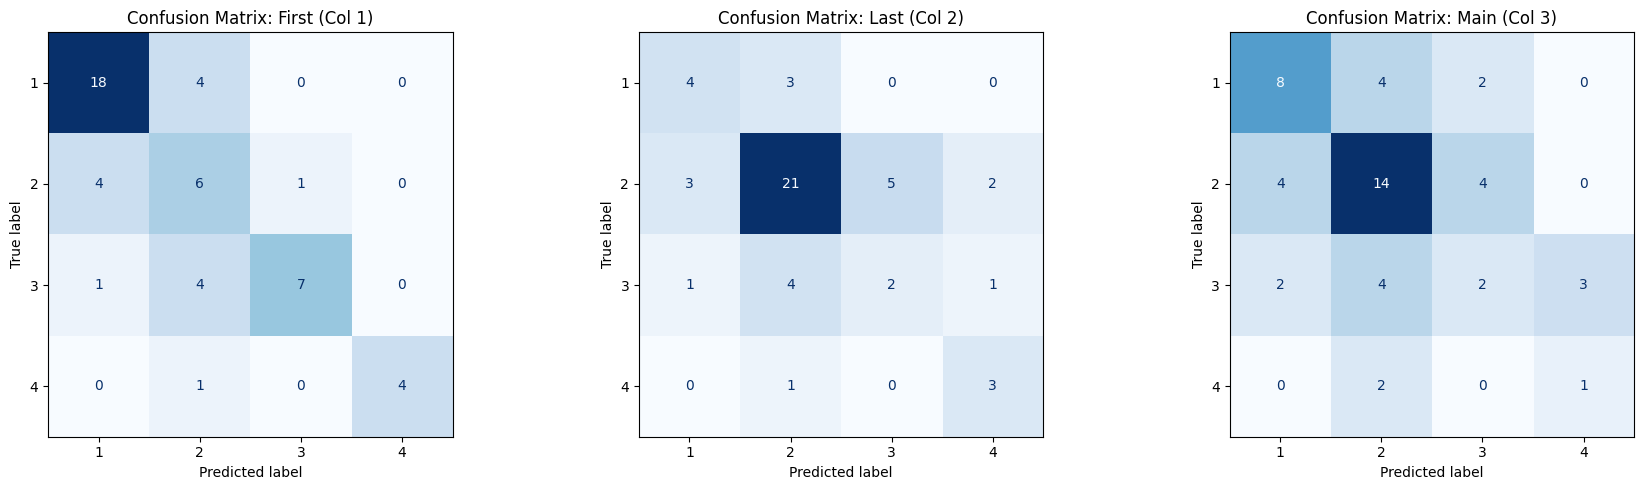

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Mapping indices to category names
categorical_cols = {
    1: "First",
    2: "Last",
    3: "Main"
}

# Explicitly define the actual class labels in your data
class_labels = [1, 2, 3, 4]

# Create a figure with 3 subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col_idx, col_name) in zip(axes, categorical_cols.items()):
    y_true = truedf.iloc[:, col_idx]
    y_pred = resdf.iloc[:, col_idx]

    # 1. Calculate the matrix, explicitly telling it to look for 1, 2, 3, 4
    cm = confusion_matrix(y_true, y_pred, labels=class_labels)

    # 2. Pass those exact same labels to the display function
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)

    # Render on the specific subplot axis
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix: {col_name} (Col {col_idx})')

# Adjust layout so the plots don't overlap
plt.tight_layout()
plt.show()

In [ ]:

annolabels=[]
with open('/content/argtype - unreconciled labels.csv', 'r') as csvfile:
    csvreader = csv.reader(csvfile, delimiter=',')
    for row in csvreader:
        annolabels.append(row)

In [ ]:
annolabs=[]
for a in annolabels:
    annolabs.append([int(a[0]), int(a[1]), int(a[2]), int(a[3]), int(a[4]), int(a[5]), int(a[6]), int(a[7])])

In [ ]:
annolabs

[[4, 2, 2, 2, 2, 1, 2, 2],
 [4, 2, 2, 2, 2, 1, 3, 1],
 [6, 1, 2, 2, 2, 1, 3, 1],
 [5, 2, 2, 2, 1, 1, 1, 1],
 [5, 3, 2, 2, 2, 3, 2, 2],
 [3, 1, 2, 2, 2, 1, 2, 2],
 [4, 1, 1, 1, 2, 1, 1, 1],
 [3, 2, 2, 2, 1, 2, 2, 2],
 [6, 2, 2, 2, 2, 1, 2, 1],
 [5, 1, 3, 2, 1, 2, 2, 2],
 [4, 3, 3, 3, 2, 4, 3, 4],
 [5, 1, 1, 1, 1, 2, 2, 2],
 [4, 2, 2, 2, 1, 2, 2, 2],
 [4, 2, 2, 2, 2, 2, 2, 2],
 [5, 1, 2, 1, 2, 1, 2, 1],
 [4, 3, 4, 4, 2, 4, 4, 4],
 [5, 4, 4, 4, 2, 4, 4, 4],
 [3, 4, 4, 4, 1, 4, 4, 4],
 [4, 1, 1, 1, 2, 1, 2, 2],
 [4, 3, 3, 3, 2, 1, 3, 3],
 [4, 1, 1, 1, 1, 2, 2, 2],
 [3, 3, 2, 3, 2, 3, 2, 3],
 [6, 3, 2, 3, 3, 1, 2, 2],
 [3, 4, 2, 2, 2, 4, 3, 3],
 [5, 3, 2, 3, 2, 3, 2, 3],
 [4, 1, 2, 2, 2, 2, 3, 3],
 [4, 1, 1, 1, 3, 2, 2, 2],
 [4, 1, 2, 1, 2, 1, 2, 1],
 [3, 3, 2, 3, 2, 2, 2, 2],
 [2, 3, 2, 2, 2, 3, 2, 3],
 [6, 1, 2, 2, 3, 1, 2, 2],
 [4, 2, 1, 2, 2, 2, 2, 2],
 [5, 3, 3, 3, 1, 4, 4, 4],
 [3, 1, 1, 1, 1, 1, 1, 1],
 [3, 3, 2, 2, 2, 3, 2, 2],
 [5, 1, 1, 1, 1, 1, 1, 1],
 [5, 1, 2, 1, 2, 1, 2, 1],
 

In [ ]:
annolabdf=pd.DataFrame(annolabs)

In [ ]:
import pandas as pd
from scipy.stats import pearsonr
from sklearn.metrics import cohen_kappa_score

# --- 1. Pearson's correlation and p-value for Columns 0 and 4 ---

# scipy.stats.pearsonr cannot handle NaN (missing) values,
# so it's safest to drop them for these two columns first.
valid_pearson_data = annolabdf.iloc[:, [0, 4]].dropna()

# Calculate Pearson correlation and p-value
corr, p_value = pearsonr(valid_pearson_data.iloc[:, 0], valid_pearson_data.iloc[:, 1])

# --- 2. Cohen's Kappa for Columns 1/5, 2/6, and 3/7 ---
kappa_1_5 = cohen_kappa_score(annolabdf.iloc[:, 1], annolabdf.iloc[:, 5])
kappa_2_6 = cohen_kappa_score(annolabdf.iloc
 [:, 2], annolabdf.iloc[:, 6])
kappa_3_7 = cohen_kappa_score(annolabdf.iloc[:, 3], annolabdf.iloc[:, 7])

# --- 3. Print the results ---
print("--- Inter-Annotator Agreement Metrics ---")
print(f"Pearson Correlation (Cols 0 & 4): {corr:.4f} (p-value: {p_value:.4e})")
print(f"Cohen's Kappa       (Cols 1 & 5): {kappa_1_5:.4f}")
print(f"Cohen's Kappa       (Cols 2 & 6): {kappa_2_6:.4f}")
print(f"Cohen's Kappa       (Cols 3 & 7): {kappa_3_7:.4f}")

--- Inter-Annotator Agreement Metrics ---
Pearson Correlation (Cols 0 & 4): 0.2042 (p-value: 1.5498e-01)
Cohen's Kappa       (Cols 1 & 5): 0.4783
Cohen's Kappa       (Cols 2 & 6): 0.4921
Cohen's Kappa       (Cols 3 & 7): 0.4236


In [ ]:

fullargdata=[]
with open('/content/all_arguments.csv', 'r') as csvfile:
    csvreader = csv.reader(csvfile, delimiter=',')
    for row in csvreader:
        fullargdata.append(row)



In [ ]:
#generate prompts for full set of args and add to list

import pandas as pd

fullprompts=[]


for line in fullargdata:#iterate through samples
    fullprompts.append([str(fullargdata.index(line)), preprompt+line[0]])



In [ ]:
fullpromptdf = pd.DataFrame(fullprompts, columns=['prompt_id', 'prompt'])

In [ ]:
fullbatchid = create_batch(fullpromptdf)

Batch Created! ID: msgbatch_01EU3VjUDvuTksszTK6aZJdX


In [ ]:
out_df = process_batch_results(fullbatchid, fullpromptdf)


In [ ]:
out_df.shape

(2, 3)

In [ ]:
fullprompts

[['0',
  '\ufeffYou are a legal specialist who has been tasked with identifying and classifying types of arguments in submissions made by the parties to disputes.\nYou will be presented with the text of a party’s submissions. Your task is, first, to identify how many distinct arguments appear in the submission, and second, to classify these arguments.\nYou should first carefully review the submissions to identify how many distinct arguments appear in it. An argument for these purposes is a freestanding point which directly supports the overall position being advocated.\nYou should then consider each of those arguments to determine which of the argument types below best fits that argument. If there are elements of multiple argument types in a given argument, you should classify it based on which argument type is most significant. Significance should be judged by the number of words devoted to the relevant argument type. \nYou will be asked to report the total number of arguments, as wel

In [ ]:
out_df['completion'][0]

'Let me analyze this submission step by step to identify the distinct arguments and classify them.\n\n**Identifying Distinct Arguments:**\n\n1. **First argument** (Paragraph 2): The term "public policy" has a settled, narrow meaning in immigration law that requires specific harmful conduct threatening essential values, not general administrative guidelines. This focuses on the ordinary/established meaning of the statutory text.\n\n2. **Second argument** (Paragraph 3): Legislative history shows the Oireachtas intended to constrain executive power, and allowing "public policy" to cover routine preferences undermines this intent and violates rule of law principles. This focuses on legislative purpose and intent.\n\n3. **Third argument** (Paragraph 4): Charlie and Alex pose no individual threat to Ireland\'s interests and shouldn\'t be punished for pandemic circumstances beyond their control. This focuses on the substantive fairness/justice of the outcome for these parties.\n\n4. **Fourth 

In [ ]:
out_df.to_csv("/content/testbatch.csv")
fullresults=[]
for row in out_df['completion']:
    fullresults.append([row[row.rindex("RESPONSE: ")+10:]])

fullresults[976]=['3; 3; 3; 3'] #manually correcting one response where model output words instead of numbers

for row in fullresults:

    row.append(int(row[0][0]))
    row.append(int(row[0][3]))
    row.append(int(row[0][6]))
    row.append(int(row[0][9]))
    row.pop(0)

In [ ]:
len(fullargdata)
len(fullresults)

1200

In [ ]:
for a in range (0,1200):
    fullargdata[a].append(fullresults[a][0])
    fullargdata[a].append(fullresults[a][1])
    fullargdata[a].append(fullresults[a][2])
    fullargdata[a].append(fullresults[a][3])

In [ ]:
fullargdatadf=pd.DataFrame(fullargdata)

In [ ]:
fullargdatadf.to_csv("/content/allargslabelled.csv")

In [ ]:
out_df['completion'][976]

'Let me analyze this submission step by step to identify the distinct arguments and classify them.\n\n**Identifying distinct arguments:**\n\nThe submission explicitly uses structural markers ("First," "Second," "Third") and then a cumulative conclusion. Let me examine each:\n\n1. **First argument (credibility assessment):** This argues that Mr. Ho\'s account is credible based on: holistic assessment rather than mechanical checking, coherent narrative, medical evidence from two independent sources, and plausible explanation for discrepancies. This is about whether the factual account should be believed.\n\n2. **Second argument (practical effectiveness of protection):** This argues that the formal legal framework in Vietnam is irrelevant because the real question is practical effectiveness, given evidence of corruption and impunity.\n\n3. **Third argument (delay and documentation):** This argues that delay and limited documentation should not automatically undermine credibility, given co

In [ ]:
row

['3; SYSTEMIC; SYSTEMIC; SYSTEMIC', 3]

In [ ]:
len(fullresults)

50